# 08 · Model Evaluation

## Objective
1. Compare the tuned candidates in detail using **out-of-fold (cross-validated) predictions on the training set**.
2. Select the final model and choose a **decision threshold** that fits the business problem.
3. Evaluate the final model **once** on the untouched test set.
4. Save the final pipeline.

Why out-of-fold predictions? `cross_val_predict` gives every training customer a prediction from a model
that **did not see that customer**. We can then compare models and pick a threshold without touching the test set.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use src/churn_utils.py
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             confusion_matrix, f1_score, fbeta_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.churn_utils import MODELS_DIR, RANDOM_STATE, load_split, set_plot_style

set_plot_style()
X_train, X_test, y_train, y_test = load_split()
tuned_models = joblib.load(MODELS_DIR / "tuned_candidates.pkl")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # same folds as notebook 07
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "Gradient Boosting": "#1baf7a"}
list(tuned_models)

['Logistic Regression', 'Random Forest', 'Gradient Boosting']

## 1. Why accuracy alone is not enough

Notebook 07 showed that a model which **never predicts churn** reaches 73.5% accuracy. Accuracy counts
all correct predictions equally, so when 73.5% of customers stay, a useless model looks good.

For churn we care about:
- **Recall (churn)** — of the customers who actually churned, how many did we catch?
- **Precision (churn)** — of the customers we flagged, how many really churned? (= how much of the retention budget is well spent)
- **F1** — the harmonic mean of the two
- **ROC-AUC / PR-AUC** — ranking quality across all thresholds

## 2. Out-of-fold predictions for each tuned model

In [2]:
def classification_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
    }

oof_probs = {
    name: cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    for name, model in tuned_models.items()
}
pd.DataFrame({name: classification_metrics(y_train, prob) for name, prob in oof_probs.items()}).T.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.8039,0.6558,0.5492,0.5977,0.8459,0.6578
Random Forest,0.8030,0.6699,0.5077,0.5776,0.8468,0.6580
Gradient Boosting,0.8056,0.6721,0.5224,0.5879,0.8494,0.6673


### Confusion matrices (out-of-fold, threshold 0.5)

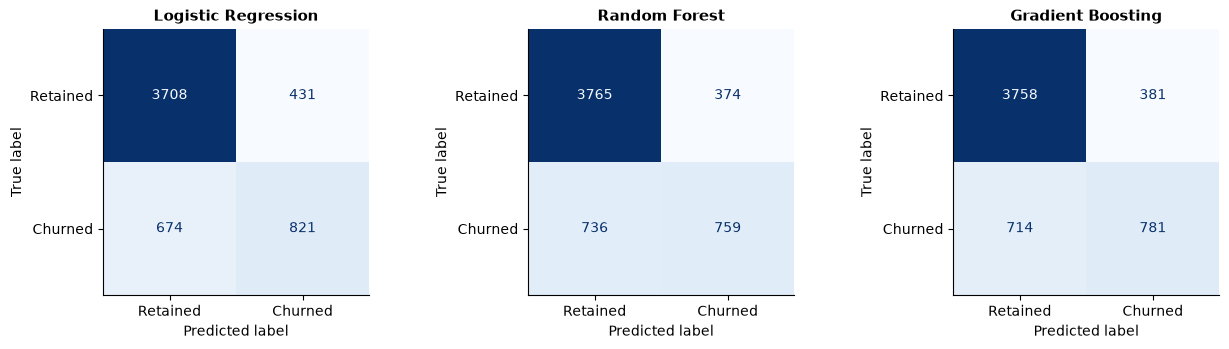

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, prob) in zip(axes, oof_probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_train, (prob >= 0.5).astype(int)),
                           display_labels=["Retained", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

### ROC and Precision-Recall curves (out-of-fold)

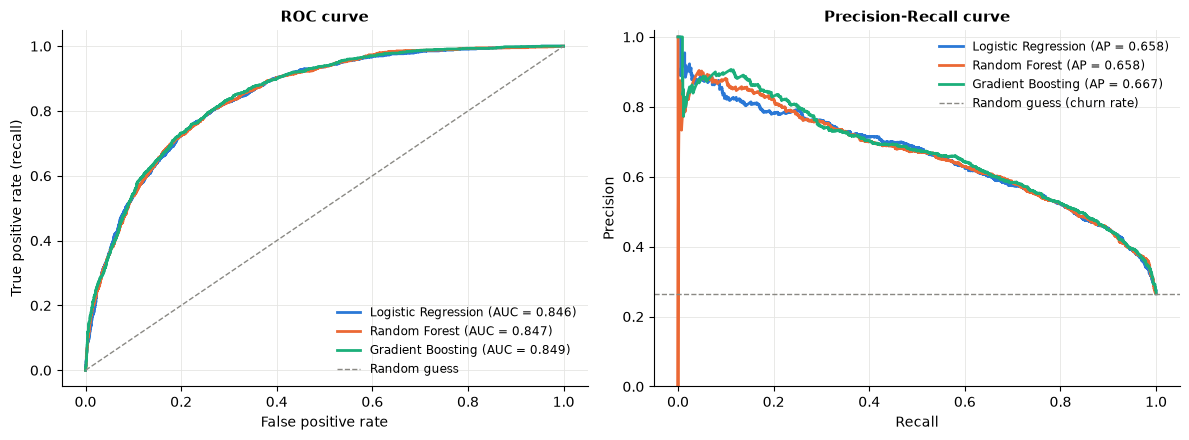

In [4]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, prob in oof_probs.items():
    fpr, tpr, _ = roc_curve(y_train, prob)
    ax_roc.plot(fpr, tpr, linewidth=2, color=MODEL_COLORS[name],
                label=f"{name} (AUC = {roc_auc_score(y_train, prob):.3f})")
    precision, recall, _ = precision_recall_curve(y_train, prob)
    ax_pr.plot(recall, precision, linewidth=2, color=MODEL_COLORS[name],
               label=f"{name} (AP = {average_precision_score(y_train, prob):.3f})")

ax_roc.plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1, label="Random guess")
ax_roc.set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate (recall)")
ax_pr.axhline(y_train.mean(), linestyle="--", color="#8a8984", linewidth=1, label="Random guess (churn rate)")
ax_pr.set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
for ax in (ax_roc, ax_pr):
    ax.grid(axis="x")
    ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

**Observations**
- The three tuned models are **almost indistinguishable**: out-of-fold ROC-AUC 0.846–0.849, PR-AUC 0.658–0.667,
  and their ROC and PR curves overlap almost everywhere.
  (Pooled out-of-fold AUCs differ slightly from the per-fold means in notebook 07 — same data, different averaging.)
- At threshold 0.5, Logistic Regression catches the most churners (821 of 1,495 → recall 0.549) at the cost of
  slightly more false alarms (431) than the tree models (374–381).
- All models **miss about half of the churners at 0.5** → the threshold must be lowered for a retention use case.

## 3. False positives vs false negatives — the business view

| Error | Meaning | Business cost |
|---|---|---|
| **False negative** | A churner predicted as "will stay" | The customer leaves without any retention attempt → **lost recurring revenue** |
| **False positive** | A loyal customer flagged as churner | A retention offer (discount, call) goes to someone who would have stayed → **cost of the offer** |

For a typical retention campaign, losing a customer costs more than an unnecessary offer, so
**false negatives are usually more expensive** → we favour **recall**, while keeping precision
reasonable so the campaign isn't wasted on mostly loyal customers.

*Assumption:* the dataset has no cost information, so this cost ratio is an assumption that the business should confirm.

## 4. Final model selection

**Selected: Logistic Regression.**

**Reasons (evidence + business):**
1. ROC-AUC and PR-AUC are within noise of Gradient Boosting (see table above and notebook 07), so the
   pre-defined rule picks the simpler model.
2. It has the **highest recall and F1** of the three at the default threshold.
3. It is **interpretable**: coefficients show which factors push risk up or down. That helps the retention
   team understand and trust the predictions (used in notebook 09).
4. It is fast and has few hyperparameters, making it easy to retrain and maintain.

In [5]:
FINAL_MODEL_NAME = "Logistic Regression"
final_pipeline = tuned_models[FINAL_MODEL_NAME]
final_oof_prob = oof_probs[FINAL_MODEL_NAME]
final_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

## 5. Choosing the decision threshold (on out-of-fold predictions)

The default 0.5 threshold catches only ~55% of churners. Since false negatives are assumed to be more
costly, we lower the threshold — but not so far that the campaign targets most of the customer base.

**Threshold rule:** *catch at least 80% of churners (recall ≥ 0.80), and among those thresholds pick the one
with the highest precision.* This turns the business goal into a concrete, explainable number.

Important: the threshold is chosen on **training out-of-fold predictions**, *not* on the test set.

In [6]:
thresholds = np.round(np.arange(0.10, 0.71, 0.05), 2)
threshold_table = pd.DataFrame([{
    "threshold": t,
    "precision": precision_score(y_train, final_oof_prob >= t),
    "recall": recall_score(y_train, final_oof_prob >= t),
    "f1": f1_score(y_train, final_oof_prob >= t),
    "f2": fbeta_score(y_train, final_oof_prob >= t, beta=2),
    "share_flagged": (final_oof_prob >= t).mean(),
} for t in thresholds])

MIN_RECALL = 0.80
eligible = threshold_table[threshold_table["recall"] >= MIN_RECALL]
BEST_THRESHOLD = float(eligible.loc[eligible["precision"].idxmax(), "threshold"])
print(f"Highest-precision threshold with recall >= {MIN_RECALL}: {BEST_THRESHOLD}")
print("For comparison, the threshold maximising F2 would be:",
      threshold_table.loc[threshold_table["f2"].idxmax(), "threshold"])
threshold_table.round(3)

Highest-precision threshold with recall >= 0.8: 0.25
For comparison, the threshold maximising F2 would be: 0.15


,threshold,precision,recall,f1,f2,share_flagged
0,0.10,0.401,0.940,0.562,0.741,0.622
1,0.15,0.438,0.914,0.592,0.751,0.553
2,0.20,0.474,0.859,0.611,0.739,0.480
3,0.25,0.509,0.817,0.627,0.729,0.426
4,0.30,0.540,0.769,0.634,0.709,0.378
5,0.35,0.571,0.720,0.637,0.684,0.334
6,0.40,0.593,0.662,0.626,0.647,0.296
7,0.45,0.624,0.603,0.613,0.607,0.256
8,0.50,0.656,0.549,0.598,0.568,0.222
9,0.55,0.689,0.486,0.570,0.517,0.187


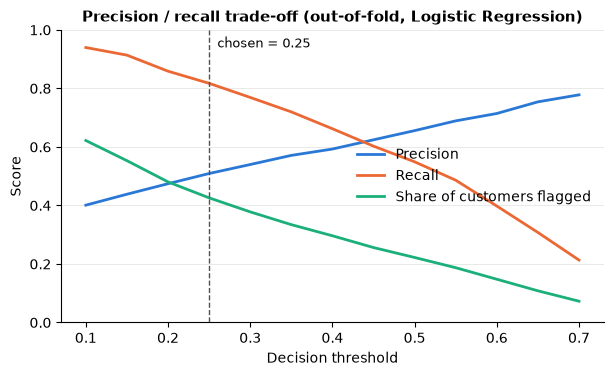

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(threshold_table["threshold"], threshold_table["precision"], linewidth=2, color="#2a78d6", label="Precision")
ax.plot(threshold_table["threshold"], threshold_table["recall"], linewidth=2, color="#eb6834", label="Recall")
ax.plot(threshold_table["threshold"], threshold_table["share_flagged"], linewidth=2, color="#1baf7a", label="Share of customers flagged")
ax.axvline(BEST_THRESHOLD, color="#52514e", linestyle="--", linewidth=1)
ax.text(BEST_THRESHOLD + 0.01, 0.94, f"chosen = {BEST_THRESHOLD}", fontsize=9)
ax.set(title="Precision / recall trade-off (out-of-fold, Logistic Regression)",
       xlabel="Decision threshold", ylabel="Score", ylim=(0, 1))
ax.legend(frameon=False, loc="center right")
plt.show()

**Observations**
- Lowering the threshold trades precision for recall. At **0.25**: recall 0.817, precision 0.509, and 42.6% of customers flagged (OOF).
- Maximising F2 would have chosen **0.15** (recall 0.914), but that flags **55% of all customers** with precision 0.44 —
  too broad to be a *targeted* retention campaign. The recall ≥ 0.80 rule gives a better balance.
- **Chosen threshold: 0.25.** If the retention budget is tighter, a higher threshold (e.g. 0.35: recall 0.72,
  precision 0.57) is a reasonable alternative; this is a business decision, and the table above supports it.

## 6. Final evaluation on the test set (used once)

The selected pipeline (already re-fitted on the full training set by `GridSearchCV`) predicts the
1,409 test customers it has never seen. The Dummy baseline is shown for reference.

In [8]:
test_prob = final_pipeline.predict_proba(X_test)[:, 1]
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_prob = dummy.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame({
    f"{FINAL_MODEL_NAME} @ {BEST_THRESHOLD} (final)": classification_metrics(y_test, test_prob, BEST_THRESHOLD),
    f"{FINAL_MODEL_NAME} @ 0.5 (reference)": classification_metrics(y_test, test_prob, 0.5),
    "Dummy baseline": classification_metrics(y_test, dummy_prob, 0.5),
}).T
test_results.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression @ 0.25 (final),0.7339,0.4992,0.8128,0.6185,0.8415,0.6288
Logistic Regression @ 0.5 (reference),0.8062,0.6593,0.5588,0.6049,0.8415,0.6288
Dummy baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654


In [9]:
# Consistency check: do test results match cross-validation expectations? (large gap -> overfitting)
pd.DataFrame({
    "cross-validation (train, OOF)": classification_metrics(y_train, final_oof_prob, BEST_THRESHOLD),
    "test": classification_metrics(y_test, test_prob, BEST_THRESHOLD),
}).T.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
"cross-validation (train, OOF)",0.7425,0.5092,0.8174,0.6275,0.8459,0.6578
test,0.7339,0.4992,0.8128,0.6185,0.8415,0.6288


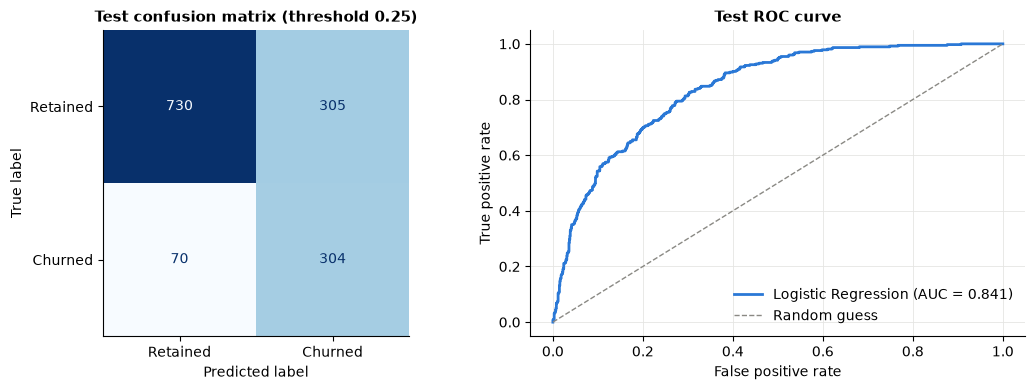

True positives  (churners caught):          304
False negatives (churners missed):          70
False positives (loyal customers flagged):  305
True negatives  (loyal, correctly ignored): 730
Customers flagged for retention: 609 of 1409 (43.2%)


In [10]:
test_pred = (test_prob >= BEST_THRESHOLD).astype(int)
cm = confusion_matrix(y_test, test_pred)
tn, fp, fn, tp = cm.ravel()

fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=["Retained", "Churned"]).plot(ax=ax_cm, cmap="Blues", colorbar=False)
ax_cm.set_title(f"Test confusion matrix (threshold {BEST_THRESHOLD})")
ax_cm.grid(False)

fpr, tpr, _ = roc_curve(y_test, test_prob)
ax_roc.plot(fpr, tpr, linewidth=2, color="#2a78d6", label=f"Logistic Regression (AUC = {roc_auc_score(y_test, test_prob):.3f})")
ax_roc.plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1, label="Random guess")
ax_roc.set(title="Test ROC curve", xlabel="False positive rate", ylabel="True positive rate")
ax_roc.grid(axis="x")
ax_roc.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(f"True positives  (churners caught):          {tp}")
print(f"False negatives (churners missed):          {fn}")
print(f"False positives (loyal customers flagged):  {fp}")
print(f"True negatives  (loyal, correctly ignored): {tn}")
print(f"Customers flagged for retention: {tp + fp} of {len(y_test)} ({(tp + fp) / len(y_test):.1%})")

**Observations (test set, threshold 0.25)**
- **Recall 0.813**: 304 of 374 churners are caught; 70 are missed.
- **Precision 0.499**: about half of the flagged customers actually churn (305 false alarms).
- **ROC-AUC 0.842**, PR-AUC 0.629, F1 0.619.
- **Accuracy is 0.734 — the same as the Dummy baseline (0.735)** — yet the model catches 81% of churners while
  the Dummy catches none. Another clear example of why accuracy is the wrong metric here.
- At the 0.5 reference threshold accuracy would be higher (0.806) but recall only 0.559: higher accuracy,
  worse for the business goal.
- **Test ≈ cross-validation** (recall 0.813 vs 0.817, ROC-AUC 0.842 vs 0.846) → no sign of overfitting,
  and the CV estimates were reliable.

## 7. Save the final model

The saved object is the **complete fitted pipeline** (preprocessing + model) plus the chosen threshold,
so new data in the same format as `data/churn_cleaned.csv` (without `Churn`) can be scored directly.

The model is kept as trained on the training set, so the saved artifact matches the reported test results.

In [11]:
final_artifact = {
    "pipeline": final_pipeline,
    "threshold": BEST_THRESHOLD,
    "model_name": FINAL_MODEL_NAME,
    "feature_columns": list(X_train.columns),
}
joblib.dump(final_artifact, MODELS_DIR / "best_model.pkl")

# Sanity check: reload and score the first 5 test customers
reloaded = joblib.load(MODELS_DIR / "best_model.pkl")
sample_prob = reloaded["pipeline"].predict_proba(X_test.head())[:, 1]
pd.DataFrame({"churn_probability": sample_prob.round(3),
              "flag_for_retention": sample_prob >= reloaded["threshold"],
              "actual_churn": y_test.head().values})

,churn_probability,flag_for_retention,actual_churn
0,0.049,False,0
1,0.683,True,0
2,0.050,False,0
3,0.420,True,0
4,0.023,False,0


## Conclusion

| Item | Result |
|---|---|
| Final model | Logistic Regression (C = 10), full preprocessing pipeline |
| Decision threshold | 0.25 (highest precision with OOF recall ≥ 0.80) |
| Test ROC-AUC | 0.842 |
| Test recall / precision / F1 | 0.813 / 0.499 / 0.619 |
| Test accuracy | 0.734 (Dummy: 0.735) |
| Churners caught on test | 304 of 374 |

- The model ranks customers well (ROC-AUC 0.84) and, at the chosen threshold, finds about 4 out of 5 churners.
- The price is many false positives: about one in two flagged customers would have stayed. That is acceptable only if a
  retention action costs much less than a lost customer — an assumption the business should validate.
- Saved: `models/best_model.pkl` (pipeline + threshold). The pipeline contains only scikit-learn components,
  so it loads with `joblib.load` and the same scikit-learn version — no project code needed.